## ⤵️ Installing and importing dependencies

In [14]:
!pip install --upgrade kagglehub
!pip install mglearn

In [15]:
import kagglehub
import pandas as pd
import json
from mglearn.tools import visualize_coefficients
from sklearn.linear_model import LogisticRegression
import time
import sklearn.model_selection as modsel
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import TfidfTransformer
from sklearn.preprocessing import normalize

In [16]:
path = kagglehub.dataset_download("yelp-dataset/yelp-dataset") + '/'
# !ls $path
# !head $path/yelp_academic_dataset_review.json

Using Colab cache for faster access to the 'yelp-dataset' dataset.


---
# 🗣️ TF-IDF

Baixamos e visualizamos o arquivo de reviews

In [17]:
f = open(path + 'yelp_academic_dataset_review.json')
js = []
for i in range(100000):
     js.append(json.loads(f.readline()))
f.close()
review_df = pd.DataFrame(js)
review_df

,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,KU_O5udG6zpxOg-VcAEodg,mh_-eMZ6K5RLWhZyISBhwA,XQfwVwDr-v0ZS3_CbbE5Xw,3.0,0,0,0,"If you decide to eat here, just be aware it is...",2018-07-07 22:09:11
1,BiTunyQ73aT9WBnpR9DZGw,OyoGAe7OKpv6SyGZT5g77Q,7ATYjTIgM3jUlt4UM3IypQ,5.0,1,0,1,I've taken a lot of spin classes over the year...,2012-01-03 15:28:18
2,saUsX_uimxRlCVr67Z4Jig,8g_iMtfSiwikVnbP2etR0A,YjUWPpI6HXG530lwP-fb2A,3.0,0,0,0,Family diner. Had the buffet. Eclectic assortm...,2014-02-05 20:30:30
3,AqPFMleE6RsU23_auESxiA,_7bHUi9Uuf5__HHc_Q8guQ,kxX2SOes4o-D3ZQBkiMRfA,5.0,1,0,1,"Wow! Yummy, different, delicious. Our favo...",2015-01-04 00:01:03
4,Sx8TMOWLNuJBWer-0pcmoA,bcjbaE6dDog4jkNY91ncLQ,e4Vwtrqf-wpJfwesgvdgxQ,4.0,1,0,1,Cute interior and owner (?) gave us tour of up...,2017-01-14 20:54:15
...,...,...,...,...,...,...,...,...,...
99995,pAEbIxvr6ebx2bHc1XvguA,SMH5CeiLvKx61lKwtLZ_PA,lV0k3BnslFRkuWD_kbKd0Q,4.0,0,0,0,Came here for lunch with a group. They were bu...,2018-05-30 22:28:56
99996,xH1AoE-4nf2ECGQJRjO4_g,2clTdtp-BjphxLjN83CpUA,G0xz3kyRhRi6oZl7KfR0pA,1.0,1,0,0,The equipment is so old and so felty! I just u...,2015-04-05 23:31:52
99997,GatIbXTz-WDru5emONUSIg,MRrN6DH3QGCFcDv5RENYVg,C4lZdhasjZVQyDlOiXY1sA,4.0,0,0,0,This is one of my favorite Mexican restaurants...,2016-06-04 00:59:15
99998,6NfkodAdhvI89xONXuBC3A,rnNQzeKJbvqVCsYsL10mkQ,dChRGpit9fM_kZK5pafNyA,2.0,0,0,0,Came here for brunch - had an omlette ($19 + t...,2018-06-11 12:45:08


Abrimos tambem o arquivo business, sobre os negócios e estabelecimentos

In [18]:
business_f = open(path + 'yelp_academic_dataset_business.json')
business_df = pd.DataFrame([json.loads(x) for x in business_f.readlines()])
business_f.close()
business_df

,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ","1616 Chapala St, Ste 2",Santa Barbara,CA,93101,34.426679,-119.711197,5.0,7,0,{'ByAppointmentOnly': 'True'},"Doctors, Traditional Chinese Medicine, Naturop...",None
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,87 Grasso Plaza Shopping Center,Affton,MO,63123,38.551126,-90.335695,3.0,15,1,{'BusinessAcceptsCreditCards': 'True'},"Shipping Centers, Local Services, Notaries, Ma...","{'Monday': '0:0-0:0', 'Tuesday': '8:0-18:30', ..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,5255 E Broadway Blvd,Tucson,AZ,85711,32.223236,-110.880452,3.5,22,0,"{'BikeParking': 'True', 'BusinessAcceptsCredit...","Department Stores, Shopping, Fashion, Home & G...","{'Monday': '8:0-22:0', 'Tuesday': '8:0-22:0', ..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,101 Walnut St,Green Lane,PA,18054,40.338183,-75.471659,4.5,13,1,"{'BusinessAcceptsCreditCards': 'True', 'Wheelc...","Brewpubs, Breweries, Food","{'Wednesday': '14:0-22:0', 'Thursday': '16:0-2..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
150341,IUQopTMmYQG-qRtBk-8QnA,Binh's Nails,3388 Gateway Blvd,Edmonton,AB,T6J 5H2,53.468419,-113.492054,3.0,13,1,"{'ByAppointmentOnly': 'False', 'RestaurantsPri...","Nail Salons, Beauty & Spas","{'Monday': '10:0-19:30', 'Tuesday': '10:0-19:3..."
150342,c8GjPIOTGVmIemT7j5_SyQ,Wild Birds Unlimited,2813 Bransford Ave,Nashville,TN,37204,36.115118,-86.766925,4.0,5,1,"{'BusinessAcceptsCreditCards': 'True', 'Restau...","Pets, Nurseries & Gardening, Pet Stores, Hobby...","{'Monday': '9:30-17:30', 'Tuesday': '9:30-17:3..."
150343,_QAMST-NrQobXduilWEqSw,Claire's Boutique,"6020 E 82nd St, Ste 46",Indianapolis,IN,46250,39.908707,-86.065088,3.5,8,1,"{'RestaurantsPriceRange2': '1', 'BusinessAccep...","Shopping, Jewelry, Piercing, Toy Stores, Beaut...",None
150344,mtGm22y5c2UHNXDFAjaPNw,Cyclery & Fitness Center,2472 Troy Rd,Edwardsville,IL,62025,38.782351,-89.950558,4.0,24,1,"{'BusinessParking': '{'garage': False, 'street...","Fitness/Exercise Equipment, Eyewear & Optician...","{'Monday': '9:0-20:0', 'Tuesday': '9:0-20:0', ..."


Fizemos um join entre o arquivo anterior e o arquivo de businnes (informações sobre os estabelecimentos)

In [19]:
mask = business_df['categories'].str.contains('Nightlife|Restaurants', na=False)
business_df_two = business_df[mask]

business_df_two = business_df_two.merge(review_df, on='business_id', how='inner')

business_df_reviews = business_df_two[['business_id',
                                  'name',
                                  'stars_y',
                                  'text',
                                  'categories']]


business_df_reviews['target'] = business_df_reviews['categories'].str.contains('Nightlife', na=False)
business_df_reviews[business_df_reviews['target']==True]

/tmp/ipykernel_330/2862968324.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  business_df_reviews['target'] = business_df_reviews['categories'].str.contains('Nightlife', na=False)


,business_id,name,stars_y,text,categories,target
17,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,4.0,"I like Tsevis because they have good gyros, wh...","Pubs, Restaurants, Italian, Bars, American (Tr...",True
18,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,4.0,Good Greek American food. I highly recomend th...,"Pubs, Restaurants, Italian, Bars, American (Tr...",True
19,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,2.0,Wife and I have eaten lunch here a few times o...,"Pubs, Restaurants, Italian, Bars, American (Tr...",True
20,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,1.0,After about 7 minutes of waiting patiently for...,"Pubs, Restaurants, Italian, Bars, American (Tr...",True
21,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,1.0,Three of us decided to try this place out last...,"Pubs, Restaurants, Italian, Bars, American (Tr...",True
...,...,...,...,...,...,...
75085,TCROPjxfzCZzrQjqLqstSg,Red Cup Cafe & Hookah Lounge,5.0,"Rick, the owner, makes crepes! And good ones ...","Coffee & Tea, Hookah Bars, Nightlife, Bars, Fo...",True
75086,TCROPjxfzCZzrQjqLqstSg,Red Cup Cafe & Hookah Lounge,3.0,"Ok, I accidentally discovered this place on my...","Coffee & Tea, Hookah Bars, Nightlife, Bars, Fo...",True
75087,TCROPjxfzCZzrQjqLqstSg,Red Cup Cafe & Hookah Lounge,5.0,"Red Cup Cafe is fantastic. Sweet or savory, c...","Coffee & Tea, Hookah Bars, Nightlife, Bars, Fo...",True
75088,TCROPjxfzCZzrQjqLqstSg,Red Cup Cafe & Hookah Lounge,5.0,Today my roommate and I stopped by Red Cup Caf...,"Coffee & Tea, Hookah Bars, Nightlife, Bars, Fo...",True


Quando o target for true, a categoria dele é Nightlife, quando for false, restaurante.

In [20]:
business_df_reviews[business_df_reviews['target']==False]

,business_id,name,stars_y,text,categories,target
0,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,4.0,This is nice little Chinese bakery in the hear...,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",False
1,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,4.0,This is the bakery I usually go to in Chinatow...,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",False
2,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,5.0,"A delightful find in Chinatown! Very clean, an...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...",False
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,5.0,I ordered a graduation cake for my niece and i...,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",False
4,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,4.0,HK-STYLE MILK TEA: FOUR STARS\n\nNot quite su...,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",False
...,...,...,...,...,...,...
75072,SVdYIdv7EWVipdqT0ifIEw,Snarf's Sandwiches - Saint Louis,1.0,Maybe I need to avoid this location all togeth...,"Restaurants, Breakfast & Brunch, Sandwiches, S...",False
75073,SVdYIdv7EWVipdqT0ifIEw,Snarf's Sandwiches - Saint Louis,5.0,They have the best milkshakes! Birthday cake f...,"Restaurants, Breakfast & Brunch, Sandwiches, S...",False
75074,dsn0I8baOgtiKX0NkeVguA,Burger King,2.0,"The staff is nice and the food is Ok, for a fa...","Restaurants, Burgers, Hot Dogs, Fast Food",False
75075,dsn0I8baOgtiKX0NkeVguA,Burger King,1.0,Terrible place. Terrible service. Terrible cus...,"Restaurants, Burgers, Hot Dogs, Fast Food",False


#### 📍 Datasets procesing

Perbece-se que existem mais estabelecimentos classificados como restaurantes. Por isso, vamos entender quanto, em porcentagem, o dataset total de nightlife representa em relacão ao de restaurantes.
Após isso, vamos pegar a mesma proporção de ambos os datasets.

In [21]:
# Create a class-balanced subsample to play with
nightlife = business_df_reviews[business_df_reviews['target']==True]
restaurants = business_df_reviews[business_df_reviews['target']==False]

print ("Nightlife: ", len(nightlife), "  Restaurants:", len(restaurants))

Nightlife:  23298   Restaurants: 51792


In [22]:
ratio = len(nightlife) / len(restaurants)
print ("Ratio nightlife / restaurants: ", ratio)

Ratio nightlife / restaurants:  0.44983781278962004


In [23]:
nightlife_subset = nightlife.sample(frac=1)
restaurant_subset = restaurants.sample(frac=ratio)

combined = pd.concat([nightlife_subset, restaurant_subset])
combined.shape

(46596, 6)

In [24]:
training_data, test_data = modsel.train_test_split(combined, train_size=0.7, stratify=combined.target)

print("Training shape: ", training_data.shape)
print("Test shape:", test_data.shape)

Training shape:  (32617, 6)
Test shape: (13979, 6)


#### 📍 Bag of Words

In [27]:
# Represent the review text as a bag-of-words
bow_transform = CountVectorizer()
X_train_bow = bow_transform.fit_transform(training_data['text']) # ATENCAO: FIT somente nos dados de TREINO e não nos de TESTE
X_test_bow = bow_transform.transform(test_data['text'])
len(bow_transform.vocabulary_)

37817

In [31]:
y_train = training_data['target']
y_test = test_data['target']

tfidf_trfm = TfidfTransformer(norm='l2')
X_train_tfidf = tfidf_trfm.fit_transform(X_train_bow)
X_test_tfidf = tfidf_trfm.transform(X_test_bow)

# Just for kicks, l2-normalize the bag-of-words representation
X_train_l2 = normalize(X_train_bow, axis=0)
X_test_l2 = normalize(X_test_bow, axis=0)

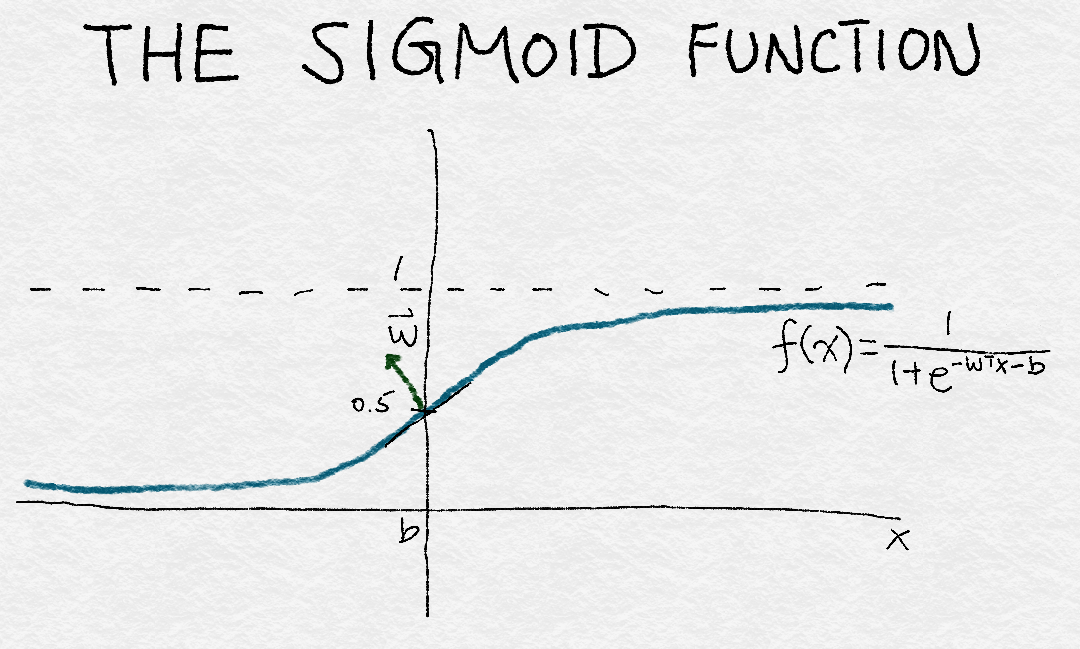

In [32]:
def simple_logistic_classify(X_train, y_train, X_test, y_test, description):
    ### Helper function to train a logistic classifier and score on test data
    print ("Processing ", description)
    t0 = time.time()
    m = LogisticRegression().fit(X_train, y_train)
    s = m.score(X_test, y_test)
    t = time.time() - t0
    print (f"Test score with {description:15}: {s:.5f} tempo: {t:.2f} segundos.\n\n")
    return m

m1 = simple_logistic_classify(X_train_bow, y_train, X_test_bow, y_test, 'bow')
m2 = simple_logistic_classify(X_train_l2, y_train, X_test_l2, y_test, 'l2-normalized')
m3 = simple_logistic_classify(X_train_tfidf, y_train, X_test_tfidf, y_test, 'tf-idf')


Processing  bow


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Test score with bow            : 0.75156 tempo: 4.42 segundos.


Processing  l2-normalized
Test score with l2-normalized  : 0.77037 tempo: 0.92 segundos.


Processing  tf-idf
Test score with tf-idf         : 0.76794 tempo: 2.33 segundos.




In [ ]:
# using bow features since we first vectorized with CountVectorizer and only
# later applied TfIdfTransformer (so we kept the feature mapping from BoW)
feature_names = bow_transform.get_feature_names_out()
feature_names

array(['00', '000', '00000', ..., '腥味大', '食べ物がすごいうまい', '鱼香茄子to'],
      dtype=object)

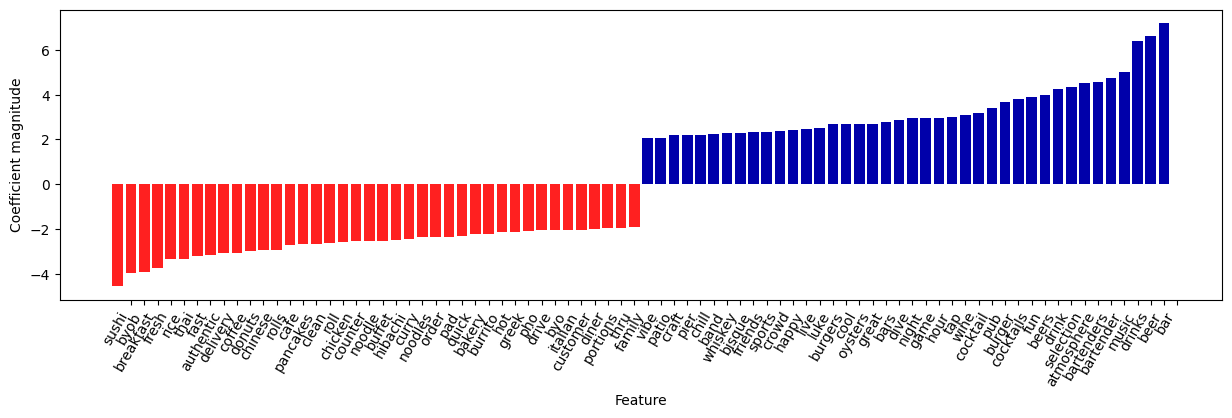

In [ ]:
visualize_coefficients(
    m2.coef_,
    feature_names,
    n_top_features=40)